# Filtering

## Instructions

### Filtrage avec une porte

1) Charger le fichier audio drums_corrupted.wav, l'écouter et le tracer
2) En passant dans le domaine fréquentiel, identifier la fréquence du sinus parasite
3) Filtrer le sinus à l'aide d'une porte de largeur $100Hz$, vérifier l'effet du filtrage en traçant le spectre obtenu
4) Revenir dans le domaine temporel, écouter

À ce stade vous devriez obtenir:

In [1]:
from IPython.display import Audio
import scipy
fs, audio = scipy.io.wavfile.read('./assets/result_1.wav')
display(Audio(audio, rate=fs))

5) Proposer une explication à l'artefact généré par le filtrage avec la porte

### Filtrage avec un IIR

6) Filtrer le fichier original, cette fois-ci à l'aide d'un filtre IIR bandstop d'ordre 2 et de largeur de Wn $100Hz$ centré sur le sinus parasite, écouter (l'artefact n'est plus sensé être présent)

### Manipulation de la phase

7) Calculer la fft du signal filtré par le IIR. Inverser (multiplier par $-1$) la phase du spectre obtenu et revenir dans le domaine temporel. Écouter et tracer le signal obtenu
8) Proposer une explication au phénomène observé

## Correction

In [2]:
# import
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio
import scipy
import math
import control 

# plot audio signal
def plot_audio(audio, fs, title=''):
    t = np.arange(len(audio))/fs
    plt.plot(t, audio)
    plt.xlabel('time (sec)')
    plt.title(title)
    plt.show()    

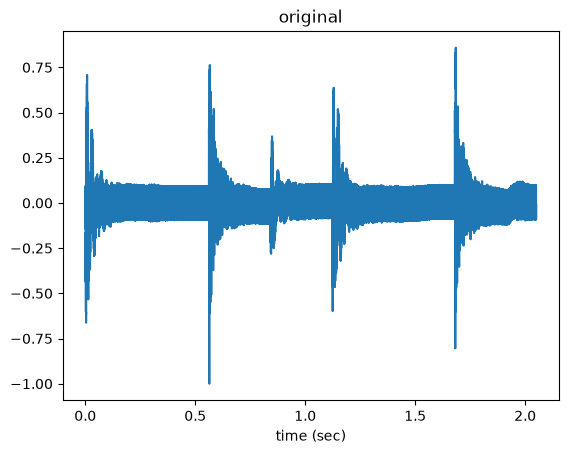

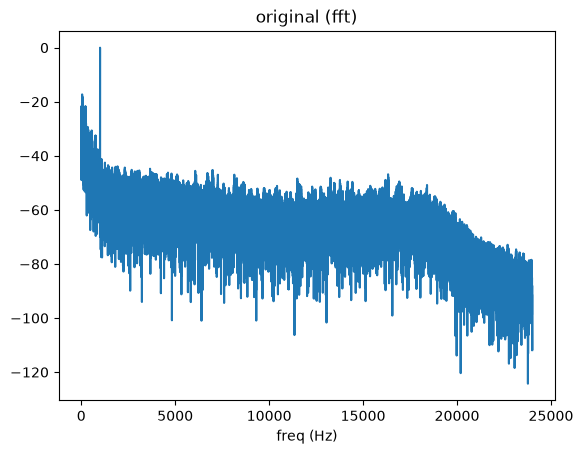

In [3]:
# load audio 
fs, audio = scipy.io.wavfile.read('./assets/drums_corrupted.wav')
audio = audio / np.max(np.abs(audio))

# play / plot
display(Audio(audio, rate=fs))
plot_audio(audio, fs, title='original')

# fft
n = len(audio)
audio_fft = np.fft.rfft(audio, n)
f = np.fft.rfftfreq(n, 1/fs)

# plot fft
x = np.abs(audio_fft) / max(np.abs(audio_fft))
plt.plot(f, control.mag2db(x))
plt.title('original (fft)')
plt.xlabel('freq (Hz)')
plt.show()

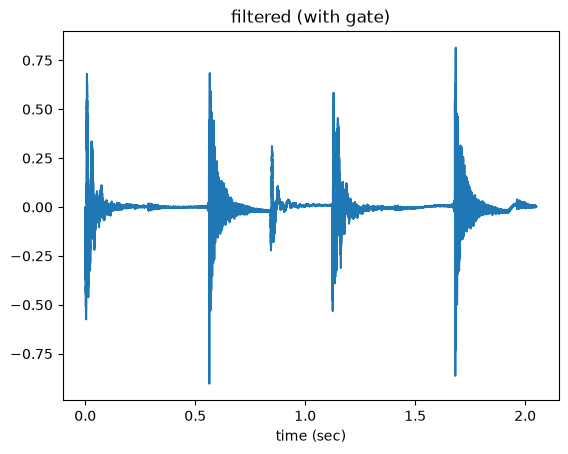

In [4]:
# filter 
gate = np.ones(len(audio_fft))
fc = 1000; o = 50
gate[ (f>(fc-o)) & (f<(fc+o)) ] = 0
audio_filtered_fft = audio_fft * gate

# ifft
n = len(audio)
audio_filtered = np.fft.irfft(audio_filtered_fft, n)

# play / plot
display(Audio(audio_filtered, rate=fs))
plot_audio(audio_filtered, fs, title='filtered (with gate)')

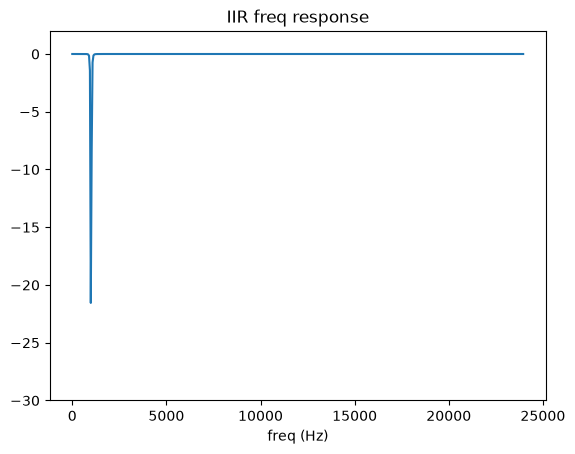

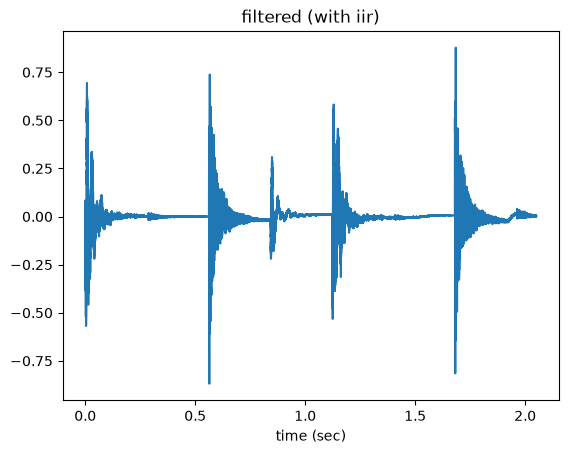

In [5]:
# better filter
fc = 1000; o = 50
b, a = scipy.signal.butter(N=2, Wn=[fc-o, fc+o], btype='bandstop', fs=fs)

# plot filter
f, H = scipy.signal.freqz(b, a, fs=fs)
plt.plot(f, 20*np.log10(abs(H)))
plt.ylim([-30, 2]); 
plt.xlabel('freq (Hz)')
plt.title('IIR freq response')
plt.show()

# filter signal 
audio_filtered = scipy.signal.lfilter(b, a, audio)

# play / plot
display(Audio(audio_filtered, rate=fs))
plot_audio(audio_filtered, fs, title='filtered (with iir)')

inverted phase


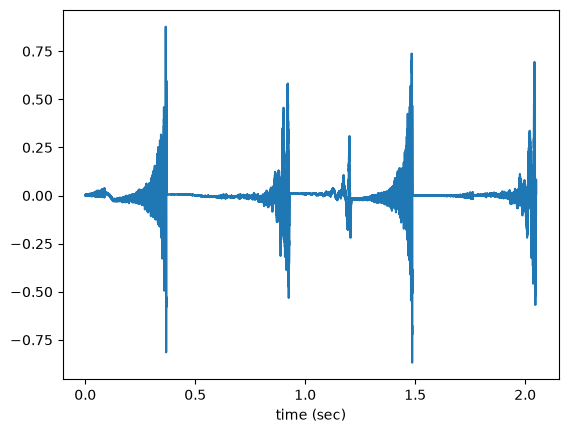

time reverse


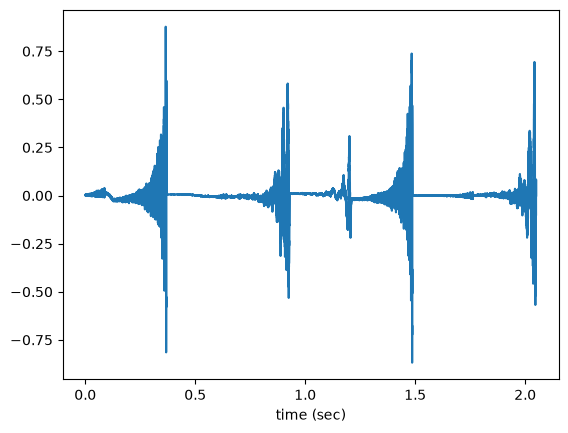

In [6]:
# invert phase
n = len(audio_filtered)
X = np.fft.rfft(audio_filtered, n)
f = np.fft.rfftfreq(n, 1/fs)
phase = -np.angle(X)
X = np.abs(X) * np.exp(1j*phase)
n = len(audio_filtered)
audio_phasemod = np.fft.irfft(X, n)

# play / plot
print('inverted phase')
display(Audio(audio_phasemod, rate=fs))
plot_audio(audio_phasemod, fs)

# time reverse
audio_timerev = audio_filtered[::-1]

# play plot
print('time reverse')
display(Audio(audio_timerev, rate=fs))
plot_audio(audio_timerev, fs)